In [ ]:
from utils.library import *
from utils.download import *
from utils.metrics import split_temporal
from utils.stock_config import *
from models.arima import *
from models.xgboost import run_xgbooster
from models.lstm import run_lstm, run_lstm_30
from utils.plots import plot_forecast, plot_forecast_30
from models.shap import explain_variables

c:\TCC\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Buscando dados

In [ ]:
vale_csv = "data/vale.csv"

if not os.path.exists(vale_csv):
    vale3_dataset = load_stock(STOCKS["vale"], "vale", force=True)
    vale3_dataset.head(10)

vale3_dataset = pd.read_csv(vale_csv)

In [ ]:
vale3_dataset

,date,vale_close,vale_high,vale_low,vale_open,vale_volume,ibovespa,vix,selic_daily,selic_goal,ipca,fx_usd,gdp,unemployment
0,2012-03-01,17.508444,17.627684,17.337533,17.397153,2644500,66810.0,17.260000,0.039270,10.5,0.21,1.7152,397757.8,8.0
1,2012-03-02,17.667425,17.711147,17.448818,17.536260,3089900,67782.0,17.290001,0.039270,10.5,0.21,1.7245,397757.8,8.0
2,2012-03-05,17.150721,17.528313,17.003657,17.512416,4268900,66964.0,18.049999,0.039270,10.5,0.21,1.7314,397757.8,8.0
3,2012-03-06,16.320017,16.685686,16.180902,16.645940,8037500,65114.0,20.870001,0.039270,10.5,0.21,1.7556,397757.8,8.0
4,2012-03-07,16.296165,16.375659,15.962293,16.375659,7283600,66017.0,19.070000,0.039270,10.5,0.21,1.7692,397757.8,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3434,2025-12-22,70.929672,71.367394,68.877263,69.091260,27853000,158142.0,14.080000,0.055131,15.0,0.33,5.5389,1084318.8,5.1
3435,2025-12-23,70.910225,71.523027,70.598959,71.231219,17140900,160456.0,14.000000,0.055131,15.0,0.33,5.5643,1084318.8,5.1
3436,2025-12-26,71.124222,71.347940,70.637869,70.871316,16368800,160897.0,13.600000,0.055131,15.0,0.33,5.5413,1084318.8,5.1
3437,2025-12-29,70.151512,71.727290,69.742970,71.192307,19963700,160490.0,14.200000,0.055131,15.0,0.33,5.5739,1084318.8,5.1


In [ ]:
print(vale3_dataset.isna().sum())

date            0
vale_close      0
vale_high       0
vale_low        0
vale_open       0
vale_volume     0
ibovespa        0
vix             0
selic_daily     0
selic_goal      0
ipca            0
fx_usd          0
gdp             0
unemployment    0
dtype: int64


## ARIMA

In [ ]:
train_vale, test_vale = split_temporal(vale3_dataset)
res_vale = run_arima(train_vale, test_vale, "vale")

--- Identificando ordem do ARIMA para VALE ---
Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=5970.913, Time=0.86 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=5967.702, Time=0.18 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=5969.683, Time=0.08 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=5969.682, Time=0.11 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=5966.962, Time=0.03 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=5971.683, Time=0.12 sec

Best model:  ARIMA(0,1,0)(0,0,0)[0]          
Total fit time: 1.418 seconds
Ordem ARIMA selecionada: (0, 1, 0)
ARIMA(0, 1, 0) vale    RMSE: 0.7749 | MAE: 0.5739 | MAPE: 1.11% | Acurácia direcional: n/a


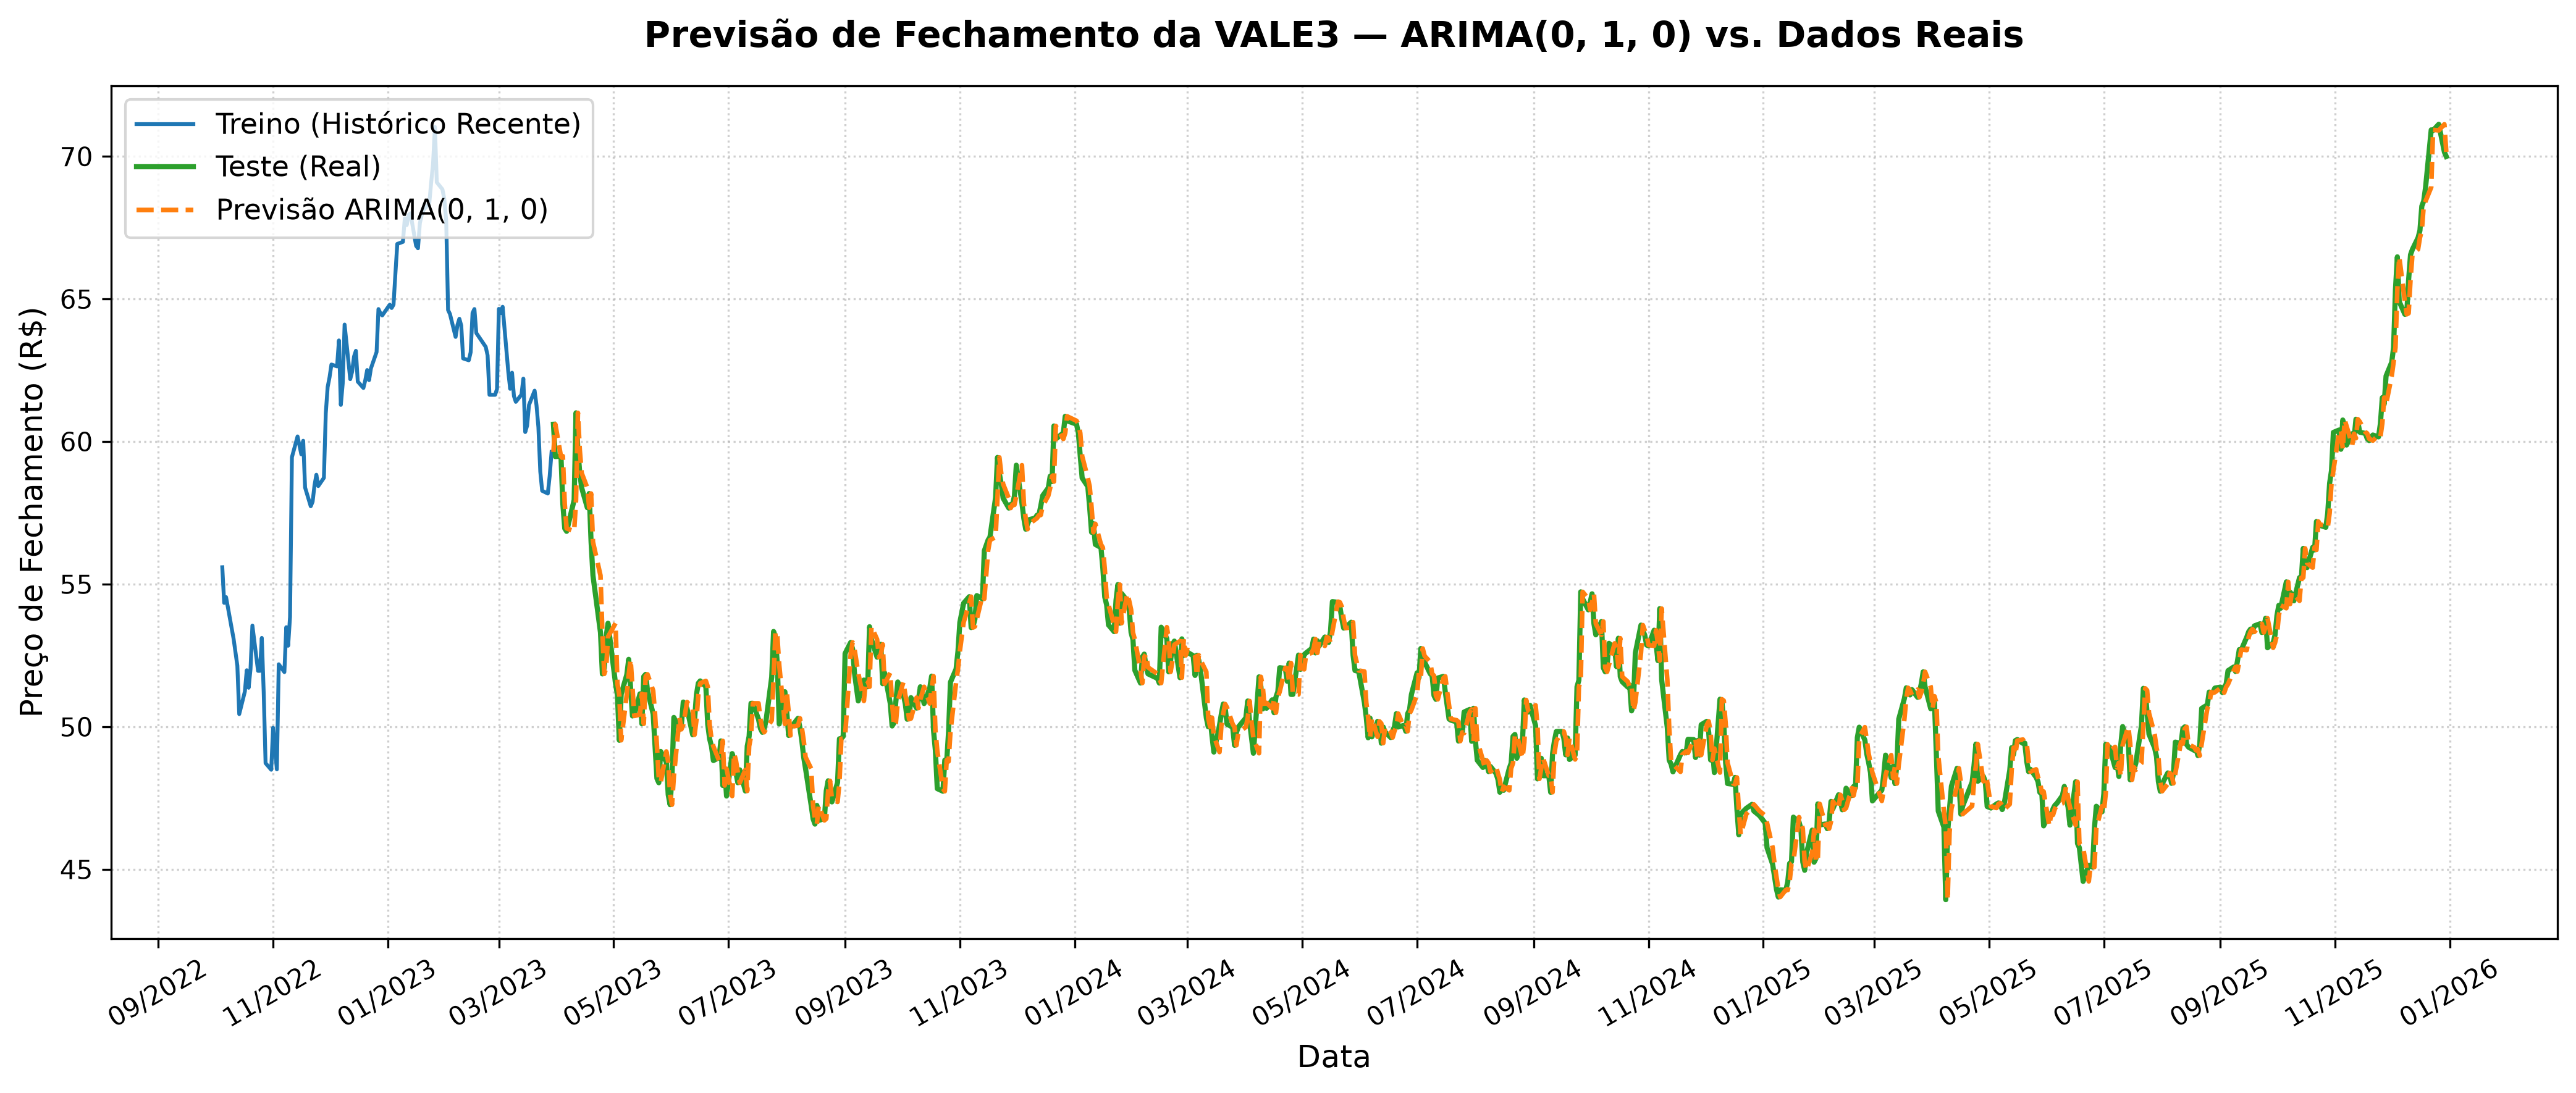

In [ ]:
plot_forecast(
    train_vale, test_vale,
    predictions=res_vale["predictions"],
    stock_name="vale",
    model_name=f"ARIMA{res_vale['order']}",
    ticker_label="VALE3",
)

## XGBooster

--- XGBoost VALE: 37 features, 2748 treino / 688 teste ---
Fitting 5 folds for each of 54 candidates, totalling 270 fits
Melhores hiperparâmetros: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100, 'subsample': 1.0}
Melhor RMSE médio (validação): 5.3444
XGBoost vale           RMSE: 0.9102 | MAE: 0.7299 | MAPE: 1.43% | Acurácia direcional: 57.85%
Naive vale             RMSE: 0.7749 | MAE: 0.5739 | MAPE: 1.11% | Acurácia direcional: n/a
p-valor (teste binomial, acurácia direcional): 0.0000


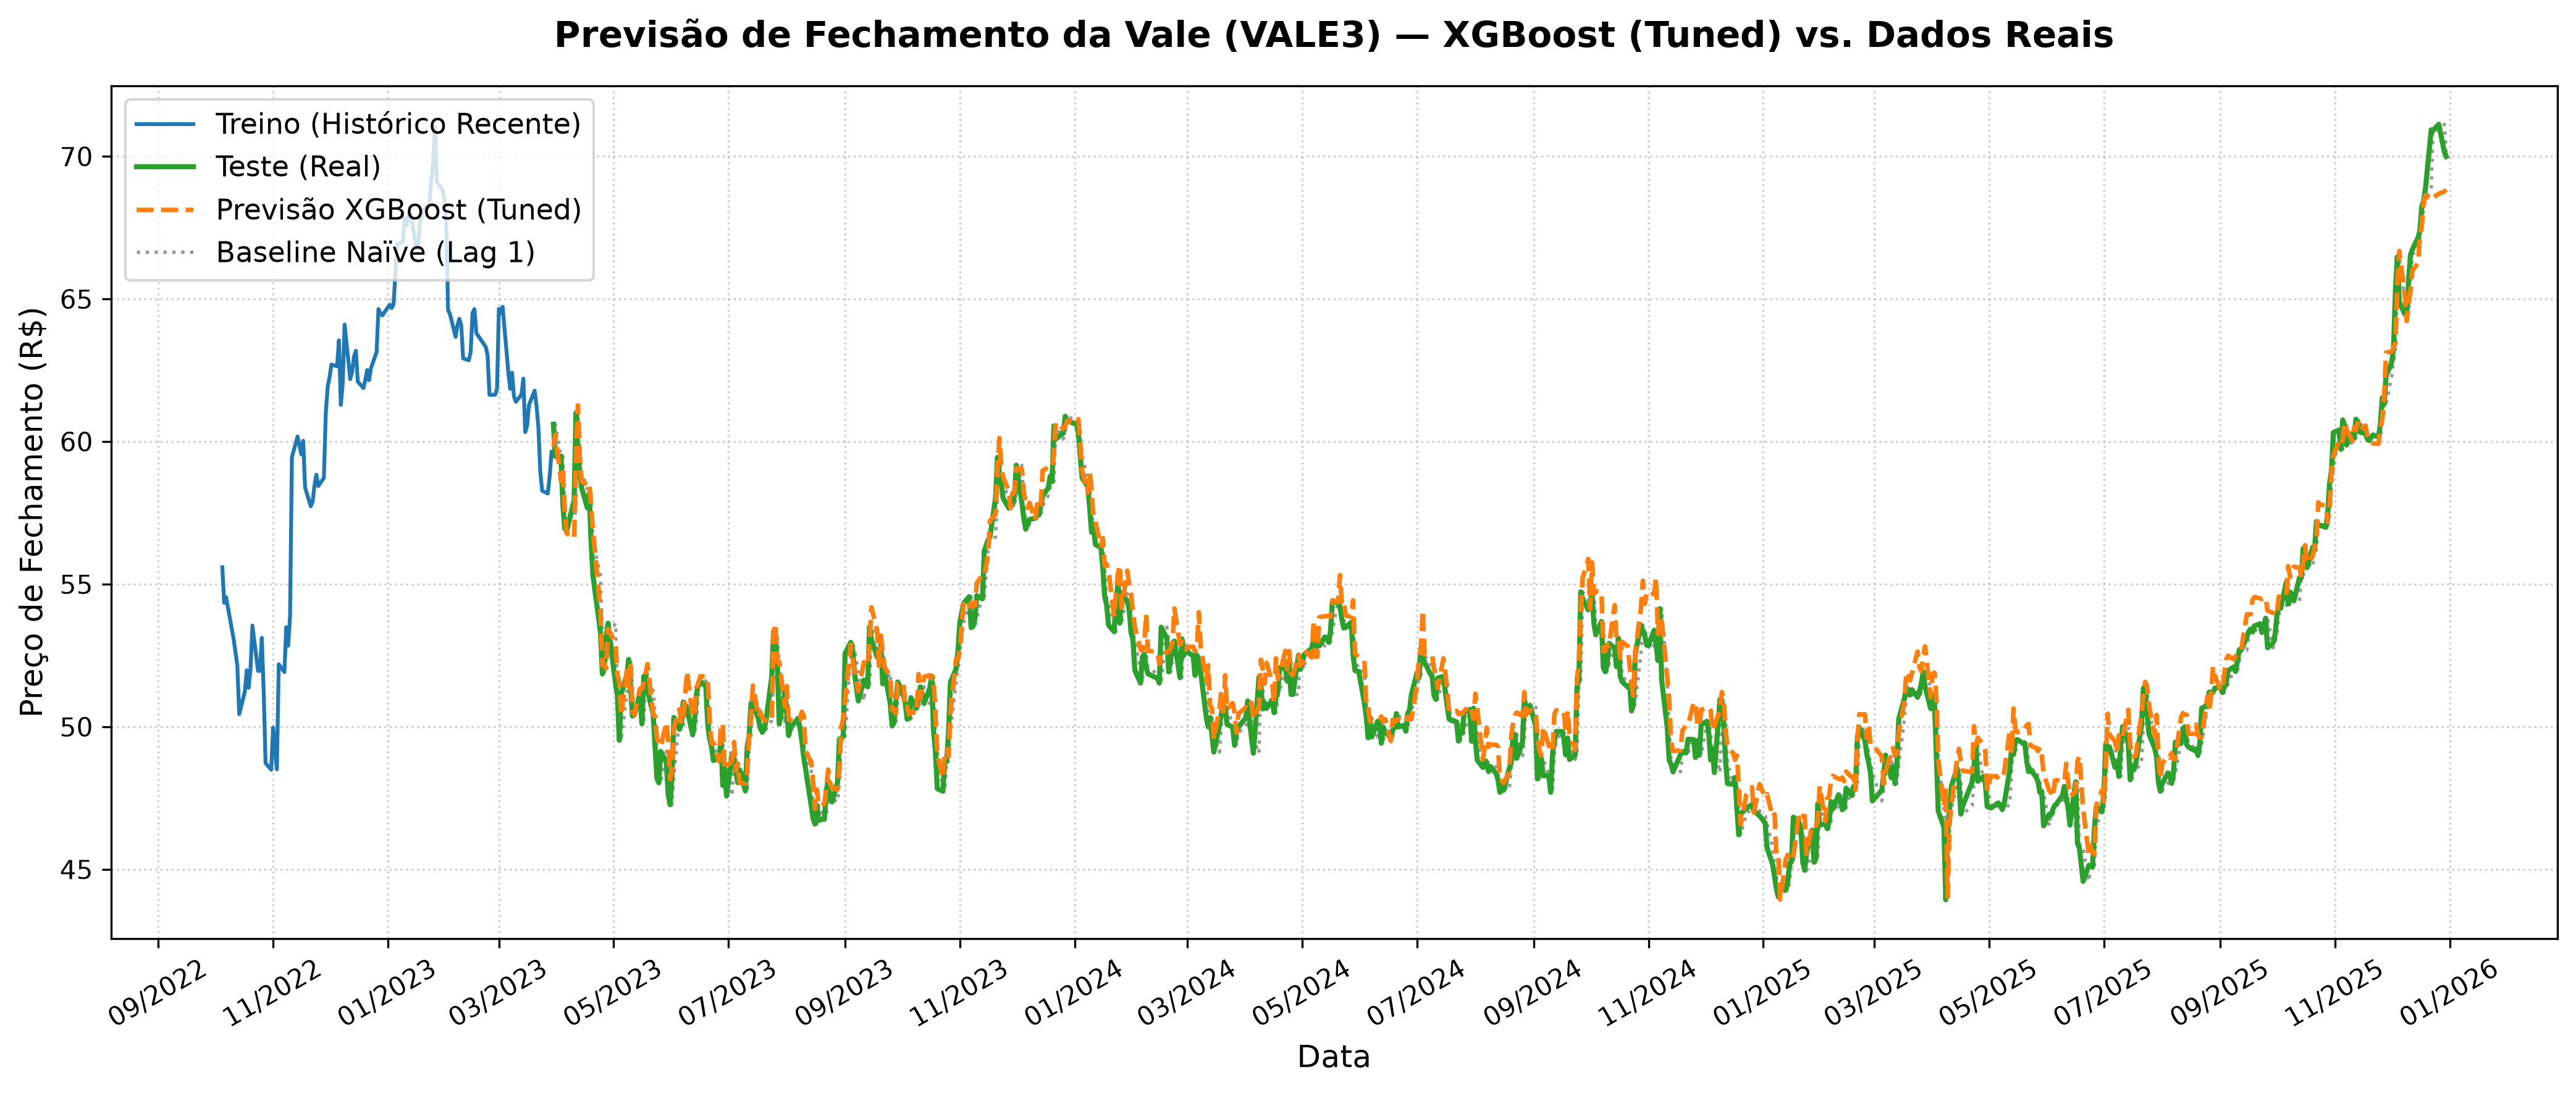

In [7]:
res_xgbooster = run_xgbooster(train_vale, test_vale, "vale")
plot_forecast(
    train_vale, test_vale,
    predictions=res_xgbooster["predictions"],
    stock_name="vale",
    model_name="XGBoost (Tuned)",
    ticker_label="VALE3",
    company_name="Vale",
    baseline=res_xgbooster["ontem"],        # baseline naive (preço de ontem)
)

Keras backend: torch | dispositivo: NVIDIA GeForce RTX 3050 6GB Laptop GPU
--- LSTM VALE: treino (2318, 20, 13), val (413, 20, 13), teste (688, 20, 13) ---
Reloading Tuner from lstm_tuning\vale_lstm\tuner0.json
Melhores hiperparâmetros: {'n_layers': 3, 'units_0': 96, 'dropout_0': 0.2, 'learning_rate': 0.01, 'units_1': 128, 'dropout_1': 0.1, 'tuner/epochs': 10, 'tuner/initial_epoch': 4, 'tuner/bracket': 2, 'tuner/round': 2, 'units_2': 32, 'dropout_2': 0.0, 'tuner/trial_id': '0012'}
Epoch 1/100
 6/37 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.3585 - mae: 0.4079 

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0646 - mae: 0.1163 - val_loss: 0.0114 - val_mae: 0.0946
Epoch 2/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0013 - mae: 0.0274 - val_loss: 0.0027 - val_mae: 0.0417
Epoch 3/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 8.1213e-04 - mae: 0.0209 - val_loss: 0.0025 - val_mae: 0.0404
Epoch 4/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 6.0287e-04 - mae: 0.0181 - val_loss: 0.0037 - val_mae: 0.0477
Epoch 5/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 5.9223e-04 - mae: 0.0181 - val_loss: 0.0030 - val_mae: 0.0434
Epoch 6/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 4.7335e-04 - mae: 0.0165 - val_loss: 0.0054 - val_mae: 0.0605
Epoch 7/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.7631e-04 - mae: 0.0180 - val_loss: 0.0057 - val_mae: 0.0615
Epoch 8/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 5.0473e-04 - mae: 0.0164 - val_loss: 0.0024 - val_mae: 0.0388
Epoch 9/100
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 11

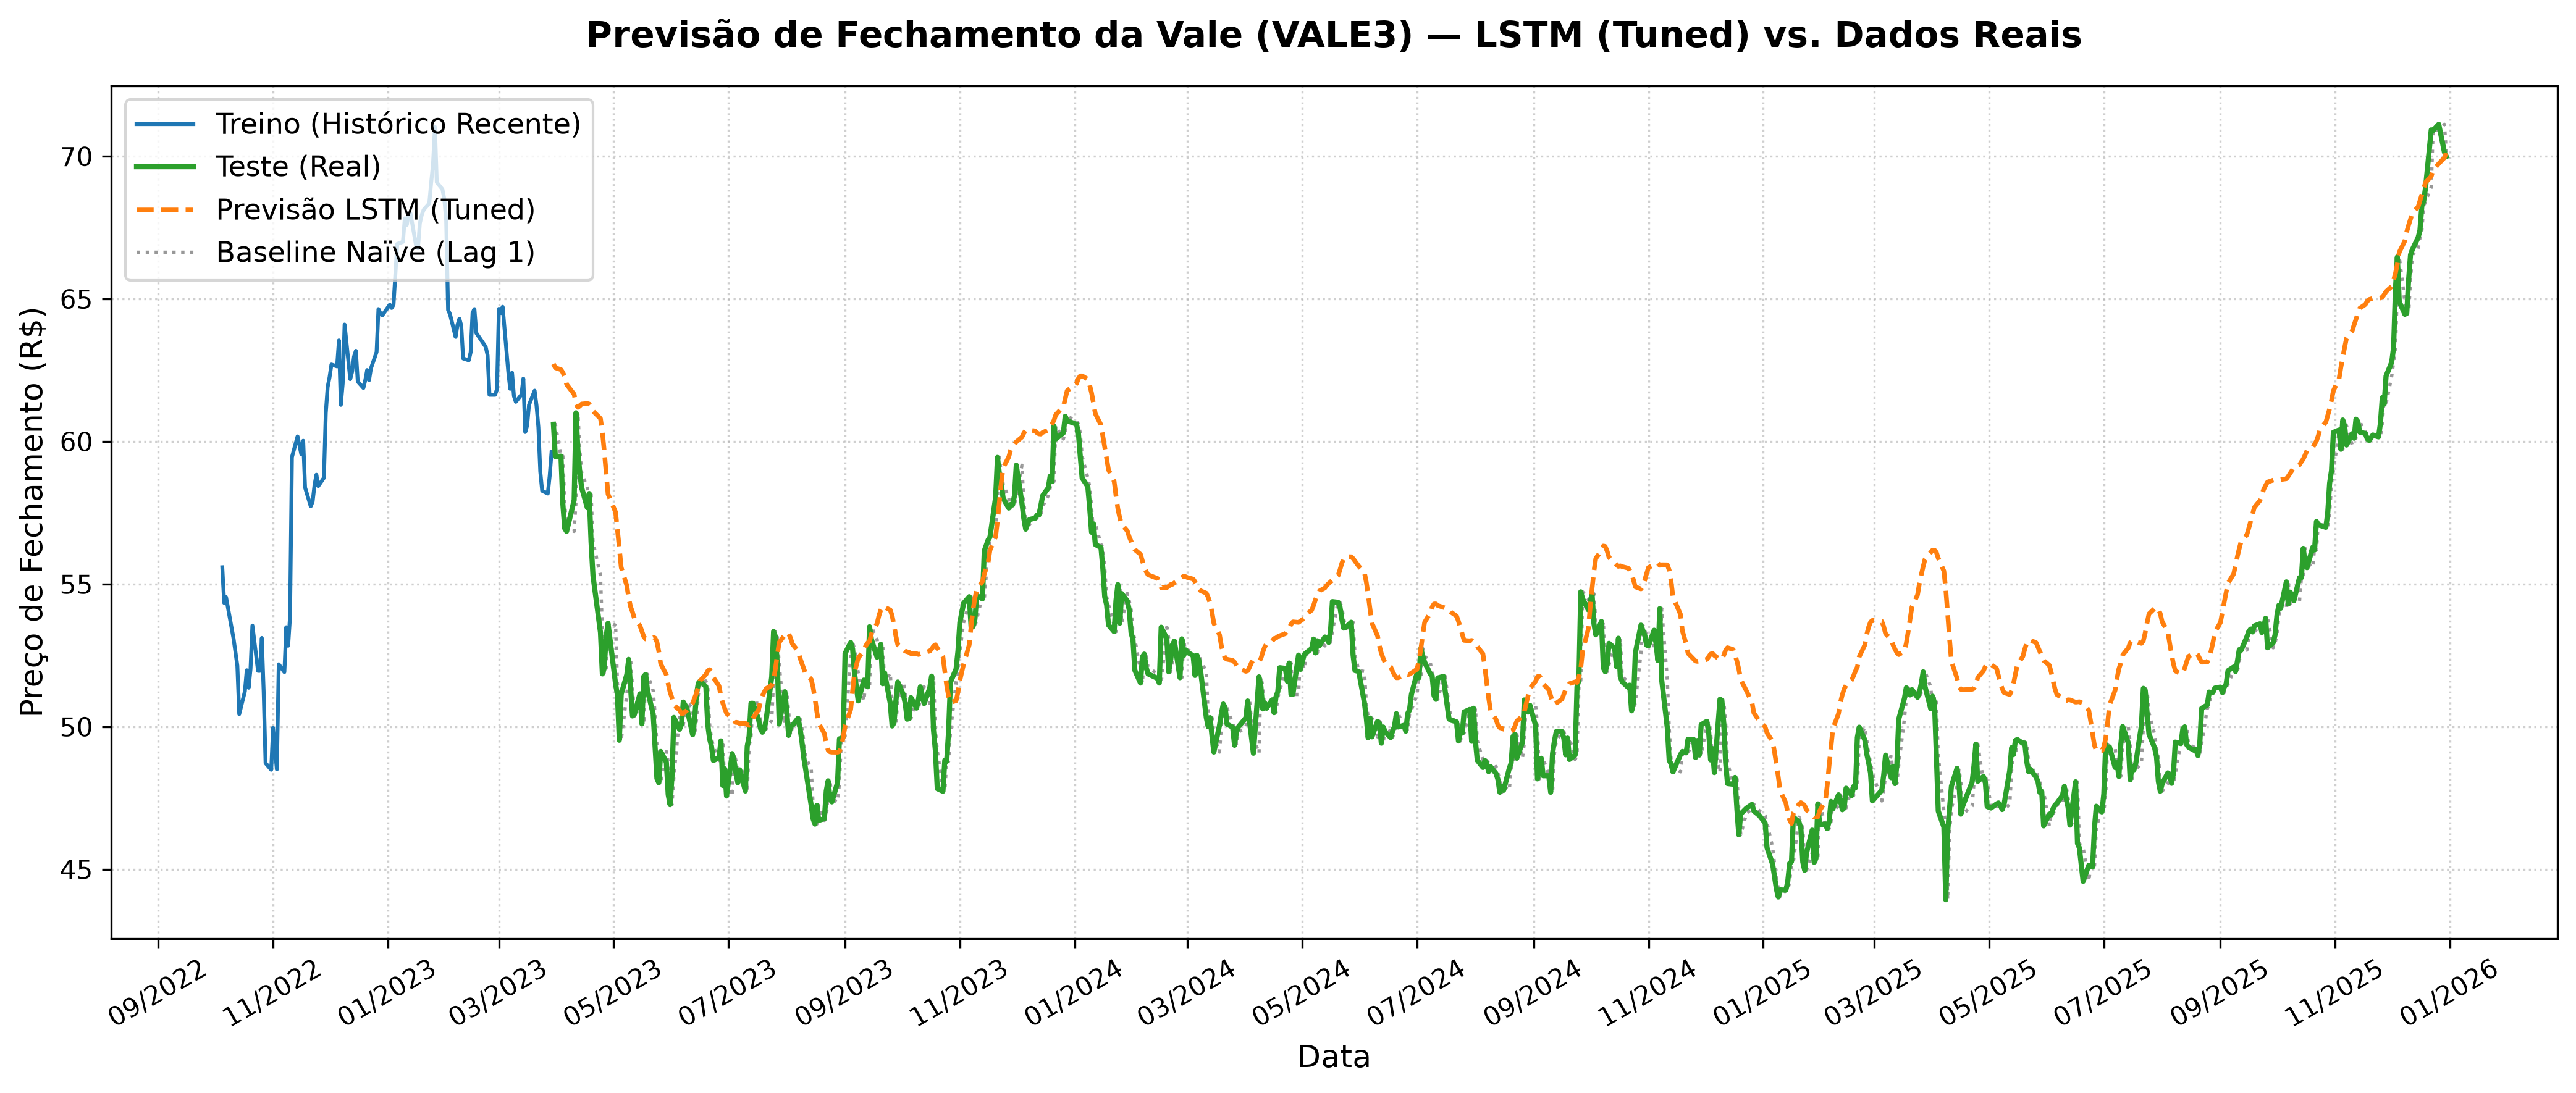

In [8]:
res_lstm = run_lstm(train_vale, test_vale, "vale", max_epochs=10)
plot_forecast(train_vale, test_vale, res_lstm["predictions"], "vale",
              model_name="LSTM (Tuned)", ticker_label="VALE3",
              company_name="Vale", baseline=res_lstm["ontem"])

In [9]:
res_lstm_30 = run_lstm_30(train_vale, test_vale, "vale", res_lstm["best_params"])

Epoch 1/100
15/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0504

c:\TCC\venv\Lib\site-packages\keras\src\backend\torch\rnn.py:656: UserWarning: RNN module weights are not part of single contiguous chunk of memory. This means they need to be compacted at every call, possibly greatly increasing memory usage. To compact weights again call flatten_parameters(). (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\native\cudnn\RNN.cpp:1481.)
  outputs, h_n, c_n = torch._VF.lstm(


36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0244 - val_loss: 0.1232
Epoch 2/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0015 - val_loss: 0.0546
Epoch 3/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 9.7121e-04 - val_loss: 0.0431
Epoch 4/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 9.1131e-04 - val_loss: 0.0312
Epoch 5/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8.9974e-04 - val_loss: 0.0231
Epoch 6/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 7.4833e-04 - val_loss: 0.0152
Epoch 7/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 8.4306e-04 - val_loss: 0.0160
Epoch 8/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 9.9155e-04 - val_loss: 0.0263
Epoch 9/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 8.4855e-04 - val_loss: 0.0158
Epoch 10/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 7.5780e-04 - val_loss: 0.0135
Epoch 11/100
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 7.9274e-04 - val_loss: 0.0119
Epoch 12/100
36/36 ━━━━━━━━━━━

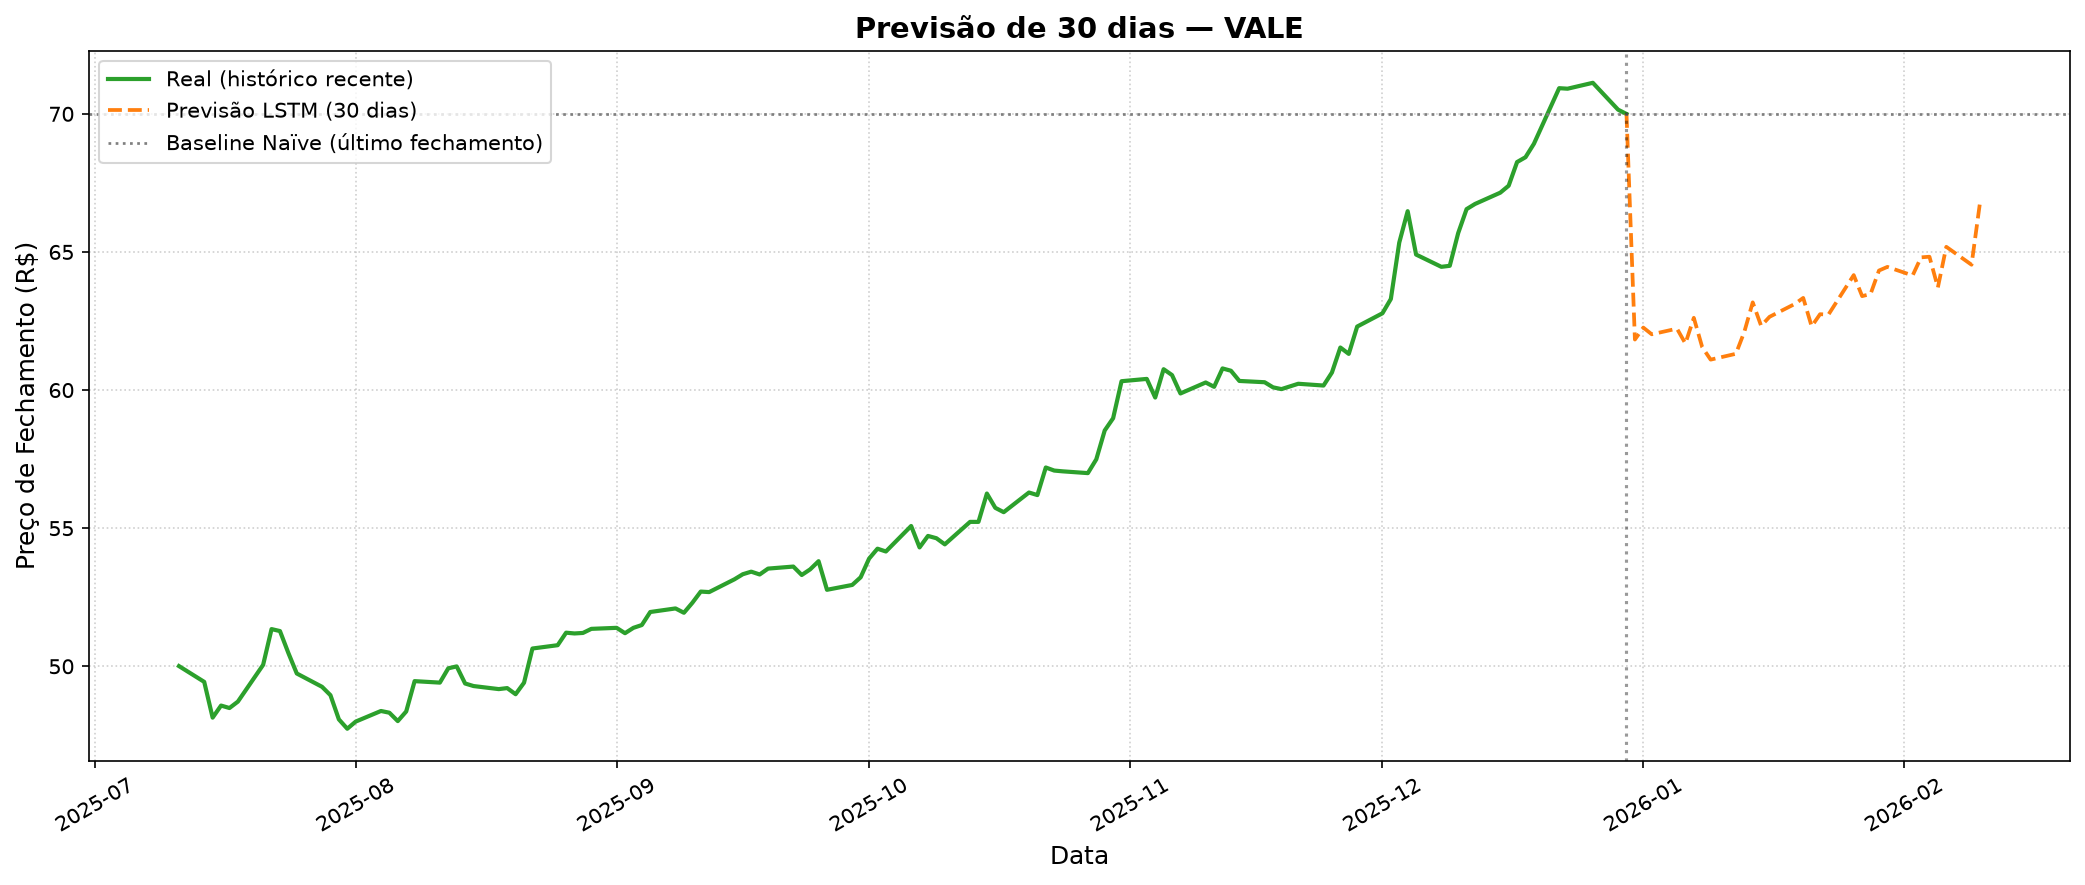

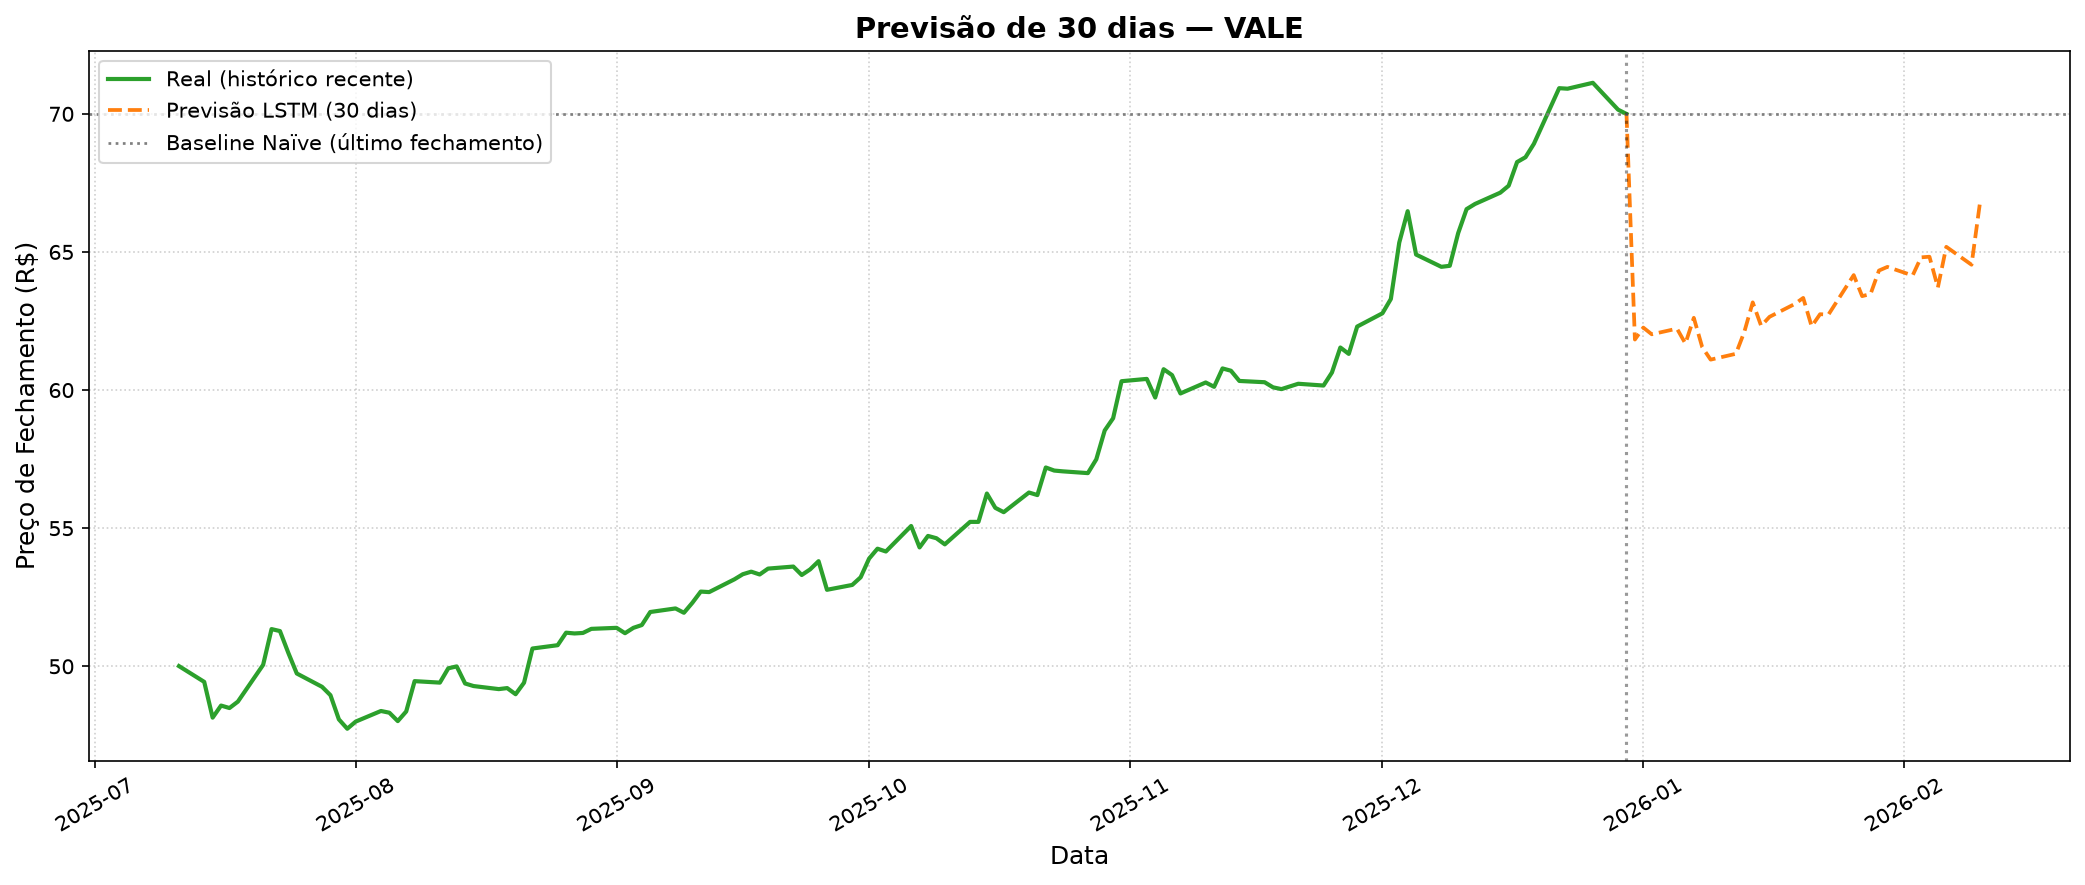

In [ ]:
res_30 = run_lstm_30(train_vale, test_vale, "vale", res_lstm["best_params"])

res_30["metricas"]                       # RMSE / MAE / MAPE por origem, com o RMSE do naive
res_30["metricas"].mean(numeric_only=True)

plot_forecast_30(res_30, train_vale, test_vale, "vale", origem="2025-03-31")   # backtest com preço real
plot_forecast_30(res_30, train_vale, test_vale, "vale")                        # previsão futura

In [11]:
tab_vale = explain_variables(res_vale)
tab_vale.head(10)

InvalidModelError: Model type not yet supported by TreeExplainer: <class 'statsmodels.tsa.arima.model.ARIMAResultsWrapper'>

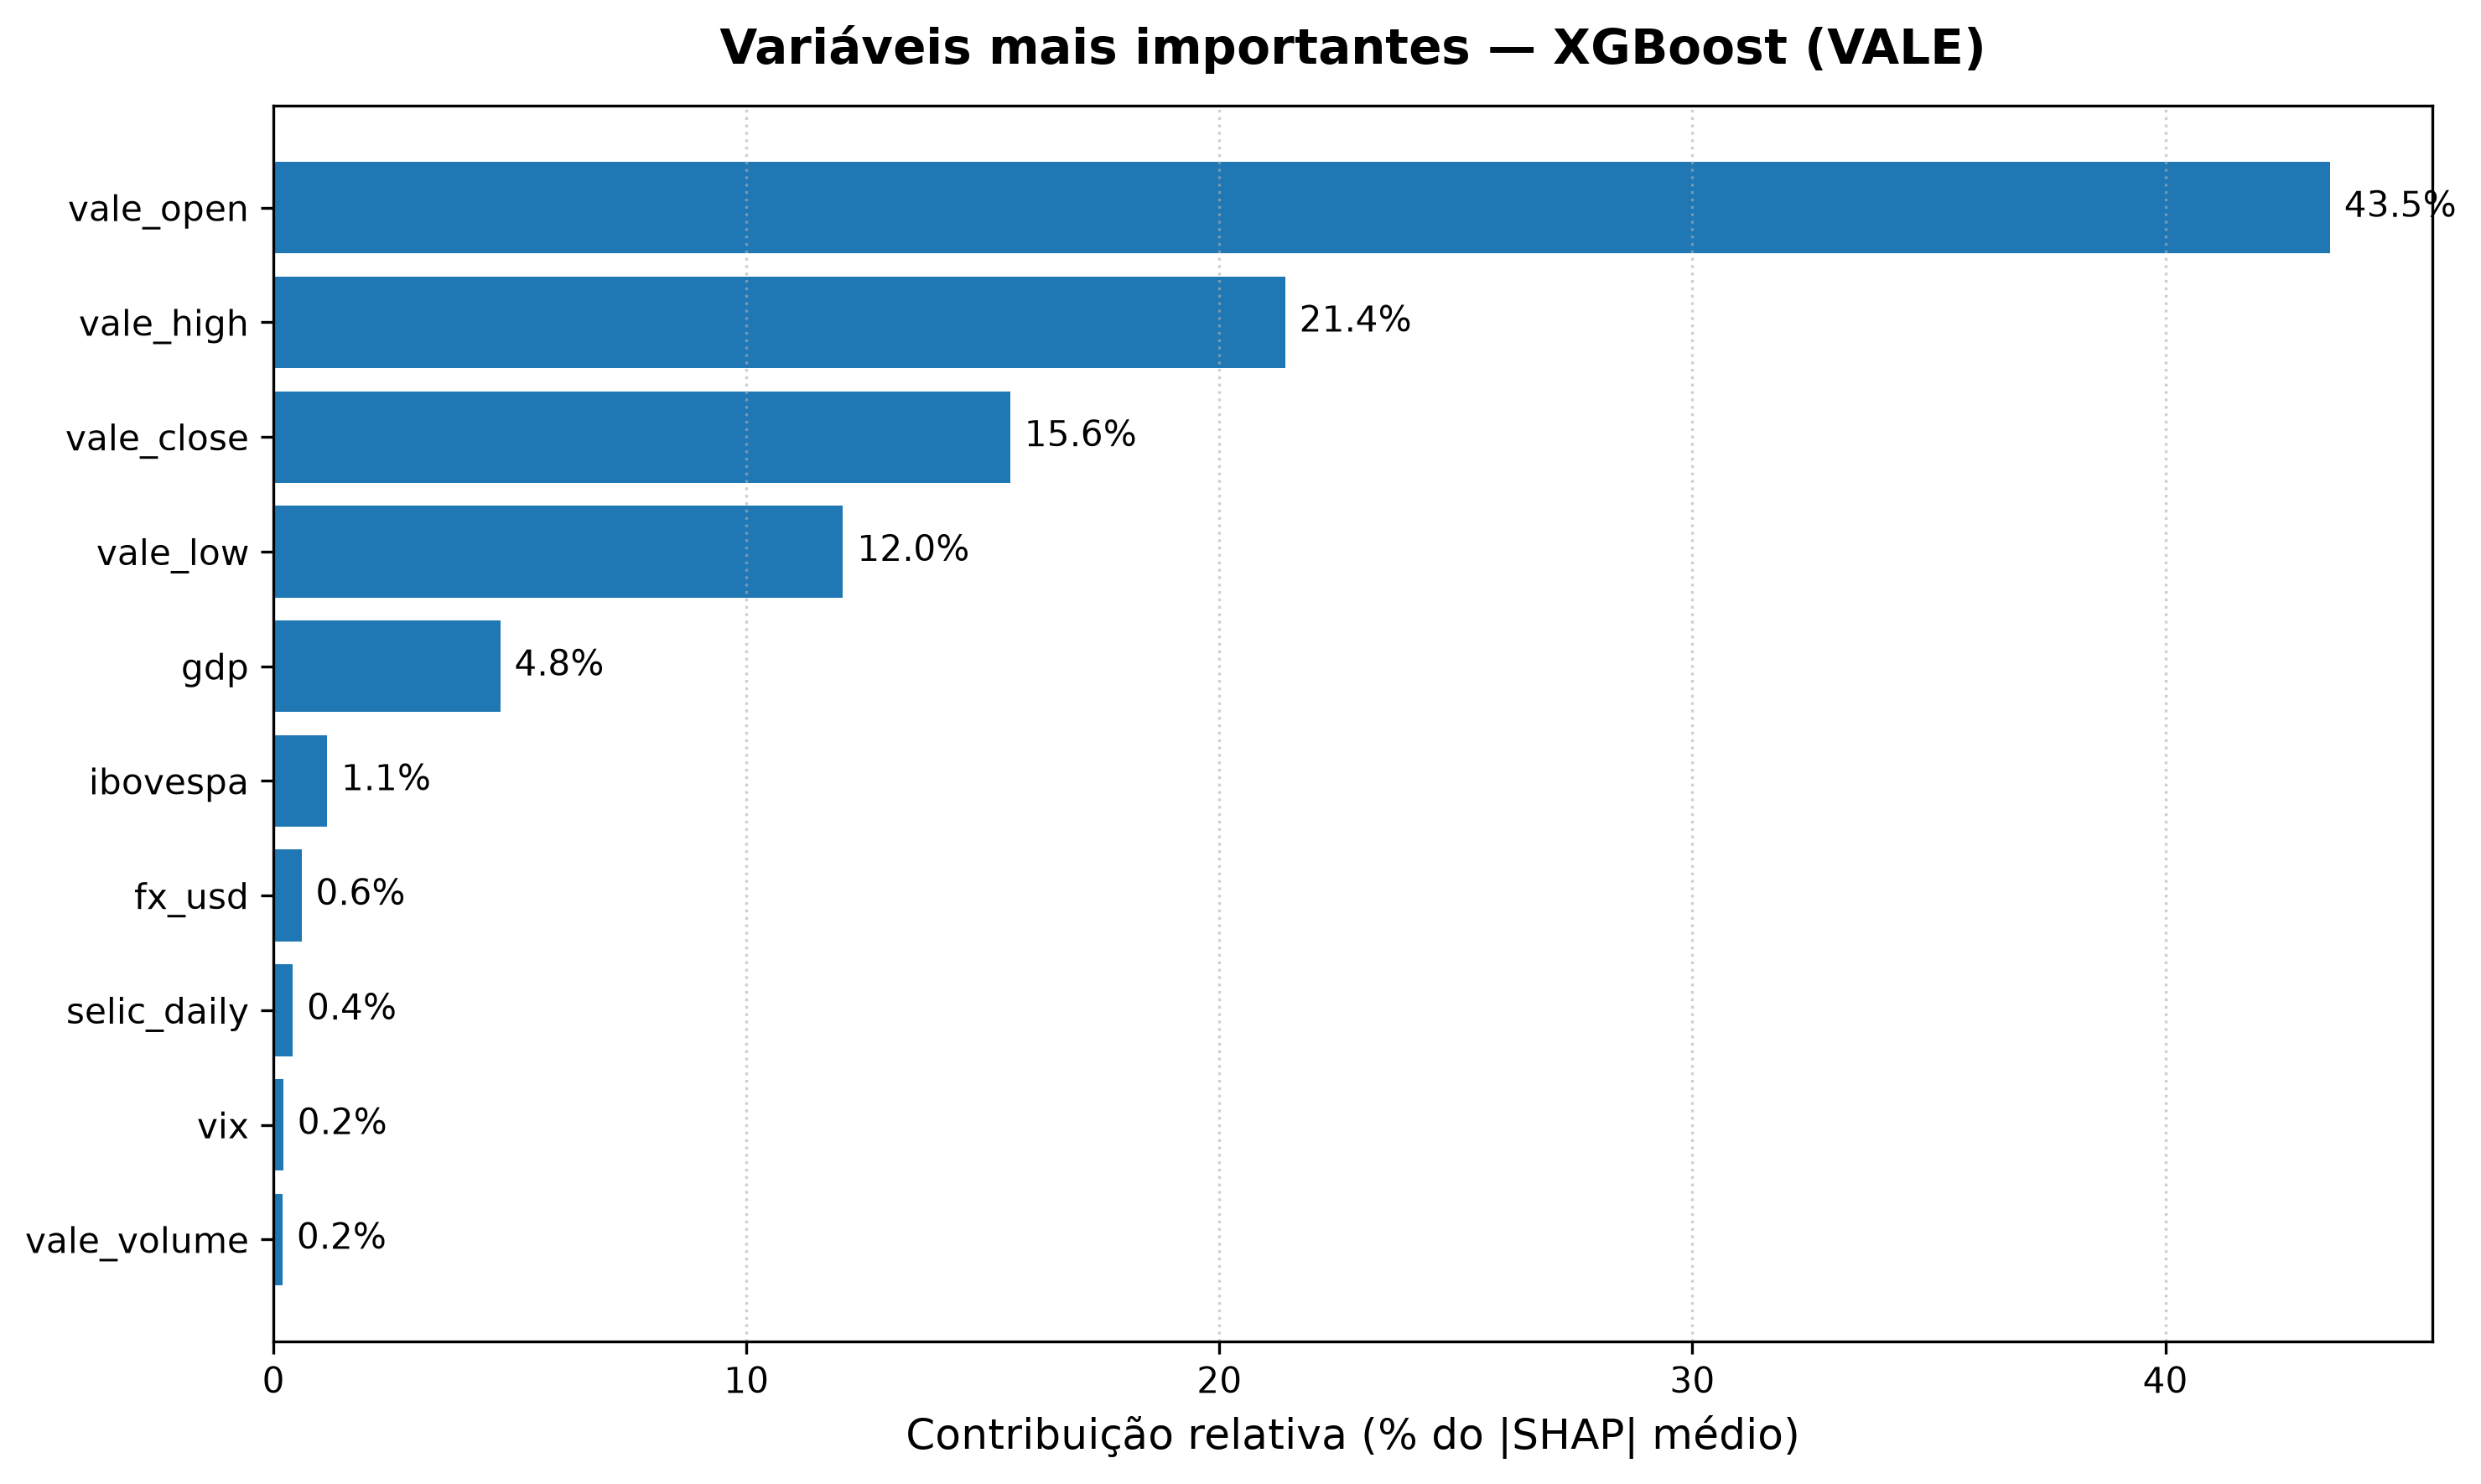

,variavel,mean_abs_shap,pct
0,vale_open,11.662192,43.479462
1,vale_high,5.737247,21.389839
2,vale_close,4.178301,15.577714
3,vale_low,3.229946,12.042019
4,gdp,1.285523,4.792738
5,ibovespa,0.303920,1.133088
6,fx_usd,0.158859,0.592263
7,selic_daily,0.109223,0.407211
8,vix,0.055552,0.207111
9,vale_volume,0.051600,0.192377


In [ ]:
tab_vale = explain_variables(res_xgbooster)
tab_vale.head(10)

In [ ]:
tab_vale = explain_variables(res_lstm)
tab_vale.head(10)